##ResNet

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import numpy as np
import cv2
import os
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from keras.applications import ResNet50V2
from keras.layers import Flatten, Dense, Dropout
from keras.models import Sequential
from keras.utils import to_categorical

In [14]:
# Veri yolu
DATADIR = "/content/drive/MyDrive/RetinalImaging/Eyes/"
CATEGORIES = ["Cataract", "Diabetic Retinopathy", "Glaucoma", "Normal"]
IMG_SIZE = 64


# Tüm veriyi depolamak için liste
all_data = []

In [15]:
# Tüm veriyi alma fonksiyonu
def create_all_data():
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        class_num = CATEGORIES.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img))
                new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                all_data.append([new_array, class_num])
            except Exception as e:
                pass

In [16]:
# Tüm veriyi oluşturma
create_all_data()

# Giriş ve çıkış verilerini ayırma
X = []
y = []
for features, label in all_data:
    X.append(features)
    y.append(label)

In [17]:
# Veriyi eğitim ve test setlerine ayırma
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

##Model Eğitme

In [18]:
from tensorflow.keras.applications import ResNet50V2
from keras.layers import GlobalAveragePooling2D, Dropout, Dense
from keras.models import Model

#res = ResNet50V2(weights='imagenet',input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False)

# ResNet50V2'nin çıktısını alarak yeni katmanları eklemeye başlama
#x = res.output

# Global Average Pooling Layer ekleme
#x = GlobalAveragePooling2D()(x)

# Dropout Layer ekleme
#x = Dropout(0.5)(x)

# Tam bağlı (fully connected) katmanlar ekleme
#x = Dense(128, activation='relu')(x)
#x = Dense(64, activation='relu')(x)

# Çıkış katmanı ekleme
#output = Dense(len(CATEGORIES), activation='softmax')(x)

# Yeni modeli oluşturma
#res = Model(inputs=res.input, outputs=output)

# Modeli derleme
#res.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# ResNet50V2 modelini yükleyerek Sequential model oluşturma
res = Sequential()

# ResNet50V2 modelini ekleyerek yeni katmanları eklemeye başlama
res.add(ResNet50V2(weights='imagenet',input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False))

# Global Average Pooling Layer ekleme
res.add(GlobalAveragePooling2D())

# Dropout Layer ekleme
res.add(Dropout(0.5))

# Tam bağlı (fully connected) katmanlar ekleme
res.add(Dense(2048, activation='relu'))
res.add(Dense(1024, activation='relu'))

# # Çıkış katmanı ekleme
# Softmax ekleyince accuracy 30'a düşüyor.
# res.add(Dense(len(CATEGORIES), activation='softmax'))

res.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [19]:
# Eğitim, test ve doğrulama setleri için özellik çıkartma
train_features = res.predict(np.array(x_train))
test_features = res.predict(np.array(x_test))

27/27 [==============================] - 0s 12ms/step


In [ ]:
# Özellik vektörlerini düzleştirme
# train_features_flatten = train_features.reshape(train_features.shape[0], -1)
# test_features_flatten = test_features.reshape(test_features.shape[0], -1)

# Random Forest

In [20]:
from sklearn.ensemble import RandomForestClassifier
# Random Forest modelini oluşturma ve eğitme
rf_model = RandomForestClassifier(n_estimators=500, random_state=42)
# rf_model.fit(train_features_flatten, y_train)
rf_model.fit(train_features, y_train)

# Test verisi üzerinde sınıflandırma yapma
# rf_predictions = rf_model.predict(test_features_flatten)
rf_predictions = rf_model.predict(test_features)

# Random Forest modelinin performansını değerlendirme
rf_accuracy = accuracy_score(y_test, rf_predictions)
print("Random Forest Model Doğruluğu:", rf_accuracy)

print("Sınıflandırma Raporu (Random Forest):")
print(classification_report(y_test, rf_predictions))

Random Forest Model Doğruluğu: 0.7049763033175356
Sınıflandırma Raporu (Random Forest):
              precision    recall  f1-score   support

           0       0.75      0.76      0.76       233
           1       0.84      0.78      0.81       224
           2       0.64      0.52      0.58       188
           3       0.58      0.73      0.65       199

    accuracy                           0.70       844
   macro avg       0.71      0.70      0.70       844
weighted avg       0.71      0.70      0.70       844



# Decision Tree

In [21]:
from sklearn.tree import DecisionTreeClassifier
# Decision Tree modelini oluşturma ve eğitme
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(train_features, y_train)

# Test verisi üzerinde sınıflandırma yapma
dt_predictions = dt_model.predict(test_features)

# Decision Tree modelinin performansını değerlendirme
dt_accuracy = accuracy_score(y_test, dt_predictions)
print("\nDecision Tree Model Doğruluğu:", dt_accuracy)

print("Sınıflandırma Raporu (Decision Tree):")
print(classification_report(y_test, dt_predictions))


Decision Tree Model Doğruluğu: 0.5710900473933649
Sınıflandırma Raporu (Decision Tree):
              precision    recall  f1-score   support

           0       0.62      0.64      0.63       233
           1       0.71      0.67      0.69       224
           2       0.45      0.47      0.46       188
           3       0.48      0.48      0.48       199

    accuracy                           0.57       844
   macro avg       0.57      0.56      0.56       844
weighted avg       0.57      0.57      0.57       844



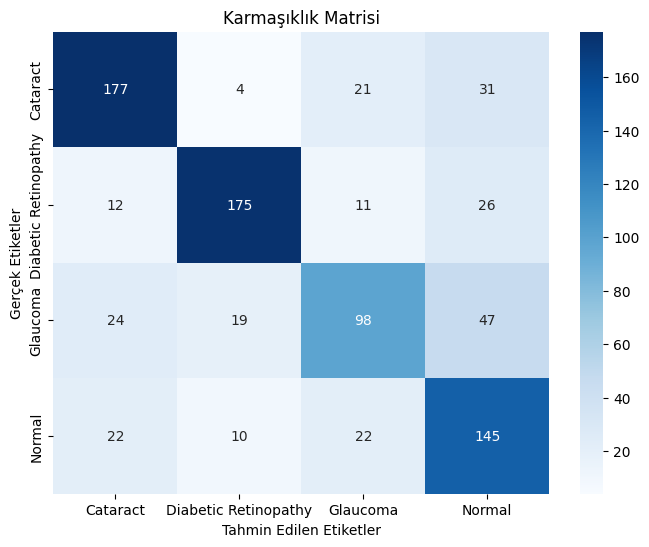

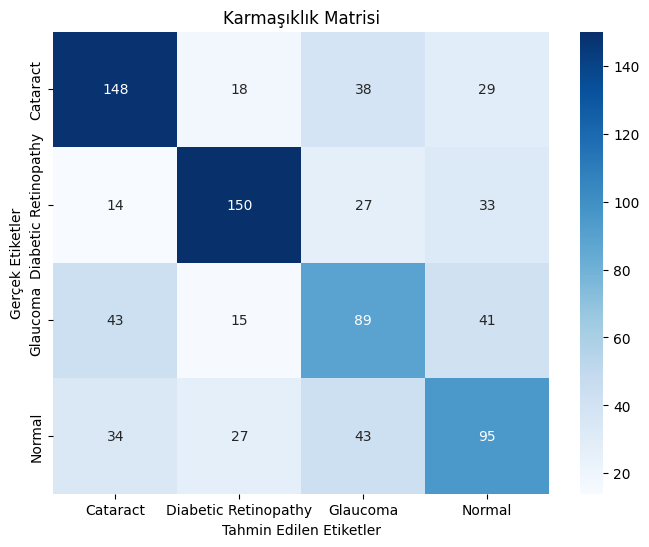

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# Karmaşıklık Matrisi (Confusion Matrix) görselleştirmesi (Random Forest)
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d", xticklabels=classes, yticklabels=classes)
    plt.xlabel('Tahmin Edilen Etiketler')
    plt.ylabel('Gerçek Etiketler')
    plt.title('Karmaşıklık Matrisi')
    plt.show()

# Karmaşıklık Matrisi görselleştirmesi (Random Forest)
plot_confusion_matrix(y_test, rf_predictions, CATEGORIES)

# Karmaşıklık Matrisi görselleştirmesi (Decision Tree)
plot_confusion_matrix(y_test, dt_predictions, CATEGORIES)